# 📊 Customer Churn Prediction

## 1. Business Understanding

### 1.1 Project Overview

In the telecom industry, customers may stop using a company's services for different reasons, such as high bills, better offers from competitors, or dissatisfaction with the service. Losing customers can affect a company's revenue, so it is important to understand why customers leave.

In this project, I will use customer data to identify patterns that may help predict whether a customer is likely to leave the company.

### 1.2 Problem Statement

One of the major challenges for telecom companies is keeping their existing customers. If the company can identify customers who are likely to leave, it may be able to take action before they discontinue the service.

The goal of this project is to analyze customer information and build a model that can help identify customers who are at risk of churning.

### 1.3 Machine Learning Objective

I will build a machine learning model that predicts whether a customer will leave the company or continue using its services. The model will use available information such as customer details, subscribed services, contract information, and billing data.

This is a **binary classification problem** because the model has to predict one of two possible outcomes: churn or no churn.

### 1.4 Target Variable

The target variable in this dataset is `Churn`.

- **Yes:** The customer has left the company.
- **No:** The customer is still using the company's services.

The model will learn from the existing customer records and use the available features to predict the target variable.

### 1.5 Model Evaluation Criteria

I will not rely only on accuracy to check how well the model performs. In customer churn prediction, it is also important to identify customers who are actually likely to leave.

For this reason, I will evaluate the model using the following metrics:

- **Recall:** Helps measure how many customers who actually churned were identified by the model.
- **Precision:** Shows how many of the customers predicted to churn actually churned.
- **F1-score:** Combines precision and recall into a single score.
- **ROC-AUC:** Measures how well the model distinguishes between customers who churn and customers who stay.

I will give particular attention to recall because failing to identify a customer who is about to leave could mean a missed opportunity to retain them. At the same time, precision is important because contacting too many customers unnecessarily can increase retention costs.

### 1.6 Expected Outcomes

Through this project, I aim to:

1. Predict which customers are more likely to leave the company.
2. Find patterns and factors that may be related to customer churn.
3. Understand how different customer characteristics affect the predictions.
4. Explore how the model's predictions could help businesses plan retention strategies.
5. Compare model performance using suitable evaluation metrics.

Finally, I will test the trained model on unseen data to understand how well it performs on customers it has not encountered during training.

In [180]:

# ================================================================
# INSTALL, IMPORT & VERIFY EDA / MACHINE LEARNING LIBRARIES
# ================================================================

import sys
import subprocess

# Step 1: Install required libraries in the current Python environment
packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "shap",
    "joblib",
]

print("Installing required libraries...\n")

subprocess.check_call([
    sys.executable, "-m", "pip", "install", *packages
])

print("\nAll package installations completed!")

# Step 2: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay,classification_report,roc_curve
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score

RANDOM_STATE = 42
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler 
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

import sklearn
import xgboost
import shap
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

# Model Selection
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    
)

# Step 3: Verify installation
print("\n" + "=" * 50)
print("LIBRARY VERIFICATION")
print("=" * 50)

print("Python executable:", sys.executable)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Matplotlib:", plt.matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("SHAP:", shap.__version__)
print("Joblib:", joblib.__version__)

# Step 4: Test basic functionality
test_df = pd.DataFrame({
    "Age": [20, 25, 30],
    "Salary": [20000, 30000, 40000],
})

assert test_df.shape == (3, 2)
assert np.mean(test_df["Age"]) == 25

print("\nDataFrame test: PASSED")
print("NumPy test: PASSED")
print("All imports successful!")



Installing required libraries...


All package installations completed!

LIBRARY VERIFICATION
Python executable: C:\Users\nisha\AppData\Local\Programs\Python\Python312\python.exe
NumPy: 2.5.4
Pandas: 2.2.3
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1
XGBoost: 3.4.1
SHAP: 0.54.1
Joblib: 1.6.0

DataFrame test: PASSED
NumPy test: PASSED
All imports successful!


### Interpretation

All required libraries have been imported and global settings have been configured to ensure consistent visualization, reproducibility, and a clean notebook environment throughout the project.


# Load dataset
### Objective

Load the IBM Telco Customer Churn dataset from the project directory, verify that it has been loaded correctly, and perform an initial inspection of its structure before data understanding and cleaning.


In [79]:
churn_df = pd.read_csv(
    r"D:\ML Project\data\WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

In [80]:
churn_df.shape

(7043, 21)

In [81]:
churn_df.shape[0]

7043

In [82]:
churn_df.shape[1]

21

In [83]:
churn_df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [84]:
RANDOM_STATE = 42


display(churn_df.sample(5, random_state=RANDOM_STATE))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
185,1024-GUALD,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,24.80,24.8,Yes
2715,0484-JPBRU,Male,0,No,No,41,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),25.25,996.45,No
3825,3620-EHIMZ,Female,0,Yes,Yes,52,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.35,1031.7,No
1807,6910-HADCM,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,No,No,No,Month-to-month,No,Electronic check,76.35,76.35,Yes
132,8587-XYZSF,Male,0,No,No,67,Yes,No,DSL,No,...,No,Yes,No,No,Two year,No,Bank transfer (automatic),50.55,3260.1,No


In [85]:
pd.DataFrame({
    "columns" : churn_df.columns
})

,columns
0,customerID
1,gender
2,SeniorCitizen
3,Partner
4,Dependents
5,tenure
6,PhoneService
7,MultipleLines
8,InternetService
9,OnlineSecurity


### Interpretation

The dataset was successfully loaded from the project directory. An initial inspection confirms its dimensions, column names, and sample records, providing a foundation for data understanding and quality assessment.


# Data Understanding
### Objective

Understand the dataset by examining its structure, data types, feature categories, summary statistics, and target variable distribution. This helps identify potential data quality issues and guides subsequent preprocessing and modeling steps.


In [86]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [87]:
unique_values = {"unique_val_counts" : churn_df.nunique()}

pd.DataFrame(unique_values).sort_values(by="unique_val_counts" )

,unique_val_counts
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


In [88]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [89]:
unique_values = {"unique_val_counts" : churn_df.nunique()}

pd.DataFrame(unique_values).sort_values(by="unique_val_counts" )

,unique_val_counts
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


In [90]:
numerical_columns = churn_df.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_columns = churn_df.select_dtypes(include=["object", "category"]).columns.tolist()
print(f"Number of Numerical Columns   : {len(numerical_columns)}")
print(f"Number of Categorical Columns : {len(categorical_columns)}")

Number of Numerical Columns   : 3
Number of Categorical Columns : 18


In [91]:
display(churn_df.describe())

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [92]:
display(churn_df.describe(include=['object']).T)

,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [93]:
display(churn_df.describe(include="all"))

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [94]:
target_counts = churn_df["Churn"].value_counts()
target_counts

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [95]:
target_percentages = churn_df["Churn"].value_counts(normalize=True).mul(100).round(2)
target_percentages

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

In [96]:
target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percentages
})

target_distribution

,Count,Percentage (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


In [97]:
majority = target_counts.max()
minority = target_counts.min()
print("Majority = ",majority)
print("Minority = ",minority)

Majority =  5174
Minority =  1869


In [98]:
imbalance_ratio = round(majority / minority, 2)
print(f"Class Imbalance Ratio: {imbalance_ratio}:1")

Class Imbalance Ratio: 2.77:1


### Interpretation

The dataset includes different types of customer information, such as personal details, account information, subscribed services, and billing details. The `Churn` column tells us whether a customer has left the company or is still using its services. Understanding how many customers belong to each group will help us get a better idea of the dataset and decide which evaluation metrics to use when building the machine learning model.

# Data Quality Assessment

### Objective

Before building the machine learning model, I will check the dataset to make sure the data is clean and reliable. This includes checking for missing values, duplicate records, incorrect data types, inconsistent category names, and columns with too many unique values. Identifying these issues early will help me prepare the data properly and avoid problems during data analysis and model training.

In [99]:
missing_summary = pd.DataFrame({
    "Missing Count": churn_df.isnull().sum(),
    "Missing Percentage (%)": (churn_df.isnull().mean()*100).round(2)})
display(missing_summary)

,Missing Count,Missing Percentage (%)
customerID,0,0.0
gender,0,0.0
SeniorCitizen,0,0.0
Partner,0,0.0
Dependents,0,0.0
tenure,0,0.0
PhoneService,0,0.0
MultipleLines,0,0.0
InternetService,0,0.0
OnlineSecurity,0,0.0


In [100]:
duplicate_count = churn_df.duplicated().sum()
print(f"Duplicate Rows: {duplicate_count}")

Duplicate Rows: 0


### Data type inspection

In [101]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Interpretation

The dataset has 21 columns containing both numerical and categorical information, with 7,043 entries in each column. At first glance, there are no missing values recorded as `NaN`. However, the `TotalCharges` column is stored as text instead of a numeric value. I will need to convert this column to the correct data type during data cleaning so that it can be used properly for further analysis and model training.

In [102]:
object_columns = churn_df.select_dtypes(include=["object"]).columns

for col in object_columns:
    blanks = (churn_df[col].str.strip()=="").sum()
    if blanks > 0:
        print(f"{col}: {blanks}")
    

TotalCharges: 11


### Interpretation

No blank strings were found in most categorical columns. However, the `TotalCharges` column contains 11 blank string values. These values are not detected by `isnull()` and will be converted to missing (`NaN`) values during the data cleaning stage before appropriate treatment.

## Check Categorical Values

### Objective

Inspect all categorical columns to identify inconsistent category values, such as different spellings, incorrect labels, leading or trailing spaces, and unexpected categories. Ensuring consistency in categorical data is essential for accurate analysis, encoding, and machine learning model performance.

In [103]:
for col in object_columns:
    print(f"Column name : {col}")
    print(churn_df[col].unique())
    print("="*80)

Column name : customerID
['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' ... '4801-JZAZL' '8361-LTMKD'
 '3186-AJIEK']
Column name : gender
['Female' 'Male']
Column name : Partner
['Yes' 'No']
Column name : Dependents
['No' 'Yes']
Column name : PhoneService
['No' 'Yes']
Column name : MultipleLines
['No phone service' 'No' 'Yes']
Column name : InternetService
['DSL' 'Fiber optic' 'No']
Column name : OnlineSecurity
['No' 'Yes' 'No internet service']
Column name : OnlineBackup
['Yes' 'No' 'No internet service']
Column name : DeviceProtection
['No' 'Yes' 'No internet service']
Column name : TechSupport
['No' 'Yes' 'No internet service']
Column name : StreamingTV
['No' 'Yes' 'No internet service']
Column name : StreamingMovies
['No' 'Yes' 'No internet service']
Column name : Contract
['Month-to-month' 'One year' 'Two year']
Column name : PaperlessBilling
['Yes' 'No']
Column name : PaymentMethod
['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
Column name : T

### Interpretation

The categorical columns were inspected for inconsistent values, unexpected categories, and formatting issues. All categorical features contain valid and consistently formatted categories, indicating that no category standardization is required. The `customerID` column is a unique identifier for each customer, while the `TotalCharges` column remains stored as a string due to the presence of blank values identified earlier.

### Check Feature Cardinality

#### Objective

Analyze the number of unique values in each feature to identify high-cardinality columns. Features with a large number of unique values, such as identifiers, generally provide little predictive value and may need to be excluded from the machine learning model.

In [104]:
display(pd.DataFrame(churn_df.nunique()).sort_values(by=0 , ascending=False))

,0
customerID,7043
TotalCharges,6531
MonthlyCharges,1585
tenure,73
PaymentMethod,4
StreamingMovies,3
TechSupport,3
OnlineBackup,3
StreamingTV,3
DeviceProtection,3


### Interpretation

The feature cardinality analysis shows that `customerID` contains a unique value for every record, confirming that it is an identifier rather than a predictive feature. This column will be removed before model training. Although `TotalCharges` and `MonthlyCharges` have many unique values, they are continuous numerical features and their high cardinality is expected. The remaining categorical features have low cardinality, making them suitable for categorical encoding during data preprocessing.

### Check Near-Zero Variance Features

#### Objective

Identify features with little or no variation in their values. Such features contribute minimal predictive information and may negatively affect model performance or unnecessarily increase model complexity.

In [105]:
for col in churn_df.columns:
    n = churn_df[col].value_counts(normalize=True).iloc[0]
    if n > 0.95:
        print(f"{col} : {n}")

### Interpretation

No near-zero variance features were identified in the dataset. This indicates that all features exhibit sufficient variability and no column needs to be removed due to a lack of informative values.

## Data Quality Summary

### Objective

Summarize the findings from the data quality assessment to identify the issues that require preprocessing before exploratory data analysis and model development.

In [106]:
data_quality_summary = pd.DataFrame({
    "Check": [
        "Missing Values (NaN)",
        "Duplicate Rows",
        "Blank Strings",
        "Data Types",
        "Categorical Values",
        "High Cardinality",
        "Near-Zero Variance"
    ],
    "Observation": [
        "No missing values detected",
        "No duplicate rows",
        "11 blank strings in TotalCharges",
        "TotalCharges stored as object",
        "No inconsistent categories",
        "customerID is a unique identifier",
        "No near-zero variance features"
    ],
    "Action Required": [
        "No",
        "No",
        "Yes",
        "Yes",
        "No",
        "Yes",
        "No"
    ]
})

display(data_quality_summary)

,Check,Observation,Action Required
0,Missing Values (NaN),No missing values detected,No
1,Duplicate Rows,No duplicate rows,No
2,Blank Strings,11 blank strings in TotalCharges,Yes
3,Data Types,TotalCharges stored as object,Yes
4,Categorical Values,No inconsistent categories,No
5,High Cardinality,customerID is a unique identifier,Yes
6,Near-Zero Variance,No near-zero variance features,No


### Interpretation

The data quality assessment shows that the dataset is generally clean and suitable for analysis. No missing values, duplicate records, inconsistent categorical values, or near-zero variance features were identified. However, three issues require attention during data cleaning: the `TotalCharges` column contains 11 blank string values, it is stored with an incorrect data type (`object`), and the `customerID` column is a unique identifier that should be excluded from model training.

# Data Cleaning

## Objective

Prepare the dataset for exploratory data analysis and machine learning by correcting data types, handling missing values, removing unnecessary features, and ensuring that all variables are in an appropriate format for further analysis.

### Create a Working Copy

#### Objective

Create a copy of the original dataset to preserve the raw data. All cleaning and preprocessing steps will be performed on the copied dataset, ensuring that the original data remains unchanged for future reference.

In [107]:
churn_cleaned_df = churn_df.copy()

### Convert TotalCharges to Numeric

#### Objective

Convert the `TotalCharges` column from a string (`object`) to a numeric data type. Any blank string values will be converted to missing (`NaN`) values to enable proper numerical analysis and missing value treatment.

In [108]:
churn_cleaned_df["TotalCharges"] = pd.to_numeric(churn_cleaned_df["TotalCharges"] , errors="coerce")

In [109]:
churn_cleaned_df["TotalCharges"].dtype

dtype('float64')

In [110]:
print("missing values :" ,churn_cleaned_df["TotalCharges"].isnull().sum())

missing values : 11


In [111]:
churn_cleaned_df[churn_cleaned_df["TotalCharges"].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


### Remove Missing Records

#### Objective

Remove the small number of records with missing `TotalCharges` values to create a complete dataset for subsequent exploratory data analysis and machine learning. Since these records represent only a small fraction of the dataset and are logically missing, their removal is unlikely to affect the overall analysis.

In [112]:
print("shape before : ",churn_cleaned_df.shape)

churn_cleaned_df = churn_cleaned_df.dropna(subset=["TotalCharges"])

print("shape after : " ,churn_cleaned_df.shape)
print("missing values :" , churn_cleaned_df["TotalCharges"].isnull().sum())

shape before :  (7043, 21)
shape after :  (7032, 21)
missing values : 0


### Interpretation

The records with missing `TotalCharges` values were successfully removed from the dataset. Since these records represented only a very small proportion of the data (11 out of 7,043) and were logically missing, their removal has a negligible impact on the overall dataset while ensuring complete data for subsequent analysis.

### Remove Identifier Column

#### Objective

Remove the `customerID` column, as it serves only as a unique identifier and does not provide meaningful information for exploratory data analysis or machine learning model development.

In [113]:
churn_cleaned_df = churn_cleaned_df.drop(columns=["customerID"])
churn_cleaned_df.shape

(7032, 20)

In [114]:
churn_cleaned_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Interpretation

The `customerID` column was successfully removed from the dataset. As a unique identifier, it does not contain predictive information and is therefore unnecessary for exploratory data analysis and machine learning model development.

# Verify the Cleaned Dataset

#### Objective

Verify that all identified data quality issues have been successfully resolved by checking the dataset structure, data types, and missing values after the cleaning process.


In [115]:
print("dataset shape",churn_cleaned_df.shape)
print("missing values", churn_cleaned_df.isnull().sum().sum())
print(churn_cleaned_df.dtypes)

dataset shape (7032, 20)
missing values 0
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


# 7. Exploratory Data Analysis (EDA)

## Target Variable Analysis

### Objective

Analyze the distribution of the target variable (`Churn`) to understand the proportion of customers who churned versus those who remained. This provides insight into the class distribution and helps determine whether class imbalance should be considered during model development.

In [116]:
target_summary = pd.DataFrame({
    "count" : churn_cleaned_df["Churn"].value_counts(),
    "percentage (%)" : churn_cleaned_df["Churn"].value_counts(normalize=True).mul(100).round(2)
})

display(target_summary)

,count,percentage (%)
Churn,,
No,5163,73.42
Yes,1869,26.58


### Visualize Target Variable Distribution

#### Objective

Visualize the distribution of the target variable (`Churn`) to better understand the class balance within the dataset. A graphical representation makes it easier to compare the number of customers who churned versus those who remained and supports the findings from the summary statistics.

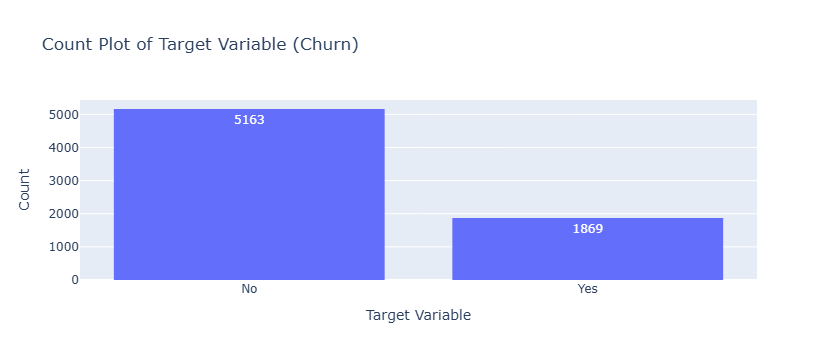

In [117]:
fig = px.histogram(
    churn_cleaned_df,
    x="Churn",
    title="Count Plot of Target Variable (Churn)",
    labels={
        "Churn": "Target Variable",
        "count": "Count"
    },
    text_auto=True
)

fig.update_layout(
    xaxis_title="Target Variable",
    yaxis_title="Count"
)

fig.show()

## Analyze Numerical Features

### Objective

Explore the numerical features in the dataset by examining their statistical summaries and distributions. This analysis helps identify the central tendency, spread, skewness, and potential outliers, providing a better understanding of the numerical characteristics of the data.

In [118]:
numerical_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
summary_statistics = churn_cleaned_df[numerical_columns].describe().T
summary_statistics["Median"] = churn_cleaned_df[numerical_columns].median()
summary_statistics["Skewness"] = churn_cleaned_df[numerical_columns].skew()
summary_statistics = summary_statistics.round(2)
summary_statistics

,count,mean,std,min,25%,50%,75%,max,Median,Skewness
tenure,7032.0,32.42,24.55,1.00,9.00,29.00,55.00,72.00,29.00,0.24
MonthlyCharges,7032.0,64.80,30.09,18.25,35.59,70.35,89.86,118.75,70.35,-0.22
TotalCharges,7032.0,2283.30,2266.77,18.80,401.45,1397.48,3794.74,8684.80,1397.48,0.96


### Interpretation

The numerical features exhibit distinct distribution characteristics:

- **tenure** has a mean of **32.42 months** and a median of **29 months**, indicating that customers typically remain with the company for around two to three years. The skewness (**0.24**) suggests a nearly symmetric distribution with a slight right skew.

- **MonthlyCharges** has an average monthly charge of **64.80**, with values ranging from **18.25** to **118.75**. The mean and median are very close, and the skewness (**-0.22**) indicates an approximately symmetric distribution with a slight left skew.

- **TotalCharges** has the highest variability, with values ranging from **18.80** to **8684.80**. The mean (**2283.30**) is substantially higher than the median (**1397.48**), and the positive skewness (**0.96**) indicates a moderately right-skewed distribution. This is expected because customers with longer tenures accumulate higher total charges over time.

### Distribution of Numerical Features


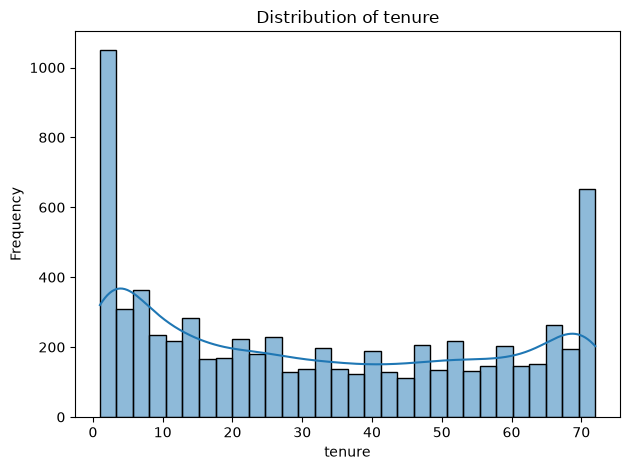

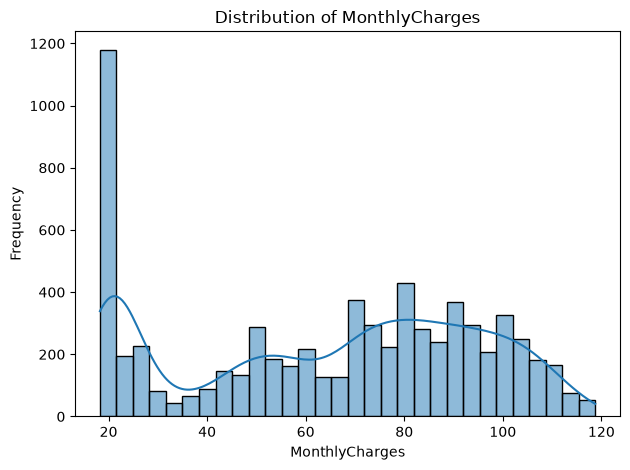

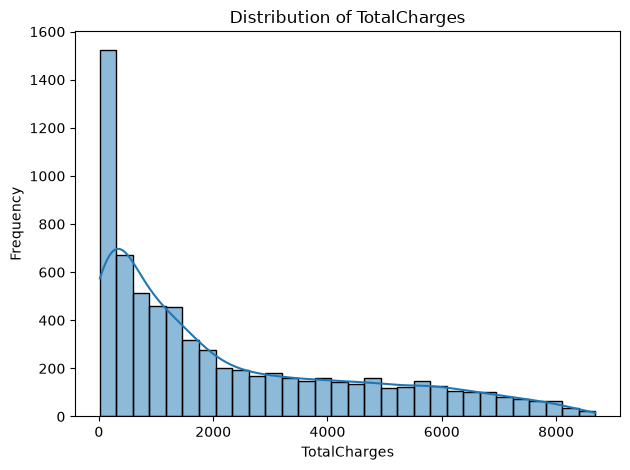

In [119]:
for col in numerical_columns: 
    sns.histplot(data=churn_cleaned_df , x=col , kde=True , bins=30) 
    plt.title(f"Distribution of {col}") 
    plt.xlabel(col) 
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

### Interpretation

The histograms reveal different distribution patterns across the numerical features:

- **tenure** exhibits a bimodal distribution, with a large number of customers having either very short or very long tenures. This indicates that the customer base consists of both recently acquired and long-term customers.

- **MonthlyCharges** shows two noticeable concentration ranges, suggesting that customers subscribe to different pricing plans or service combinations rather than being uniformly distributed across monthly charges.

- **TotalCharges** is moderately right-skewed, with most customers having relatively low total charges and a smaller number accumulating very high total charges. This pattern is expected because total charges increase as customers remain with the company for longer periods.

Overall, the histogram observations are consistent with the summary statistics, particularly the skewness values calculated earlier.

## Outlier Analysis


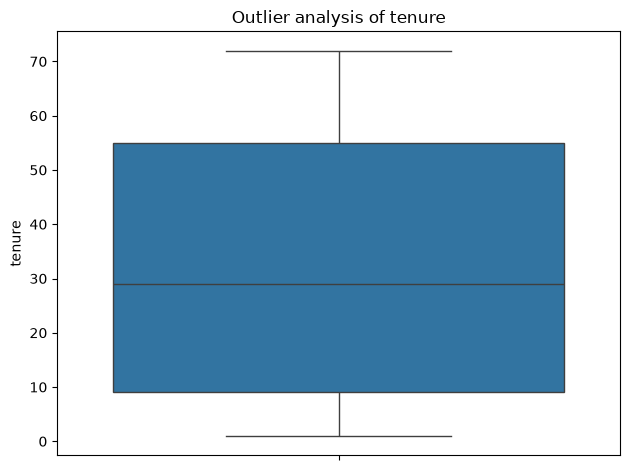

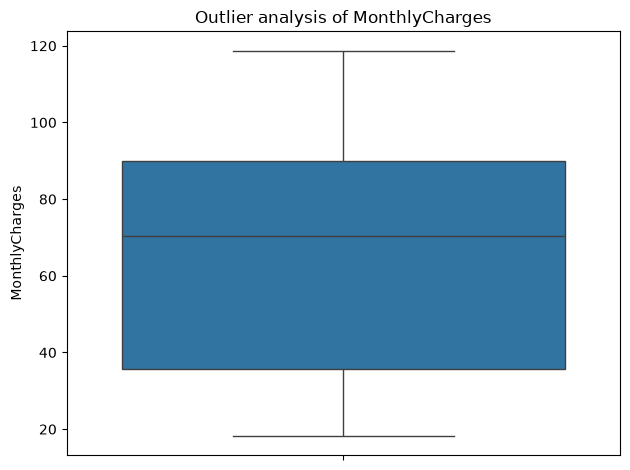

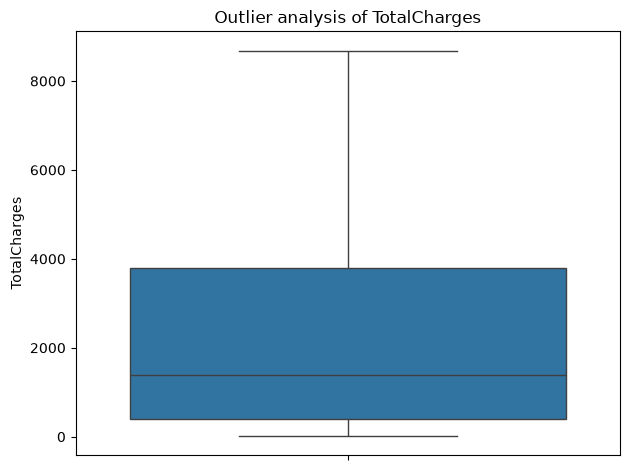

In [120]:
for col in numerical_columns:
    sns.boxplot(data=churn_cleaned_df , y=col)
    plt.title(f"Outlier analysis of {col}") 
    plt.ylabel(col) 
    plt.tight_layout()
    plt.show()

### Interpretation

The box plots indicate that the numerical features do not contain significant outliers based on the interquartile range (IQR) method.

- **tenure** shows a wide distribution of customer lifetimes without any extreme observations beyond the whiskers.

- **MonthlyCharges** exhibits a broad range of monthly billing amounts, with no unusual values detected outside the expected range.

- **TotalCharges** displays a wider spread and a longer upper whisker, reflecting its moderately right-skewed distribution. Although some customers have substantially higher total charges, these values fall within the expected range and are consistent with long customer tenures.

Overall, the box plots suggest that the extreme values are genuine customer observations rather than data anomalies. Therefore, no outlier treatment is required before model development.

## Analyze Categorical Features

Feature: gender



,Count,Percentage (%)
gender,,
Male,3549,50.47
Female,3483,49.53


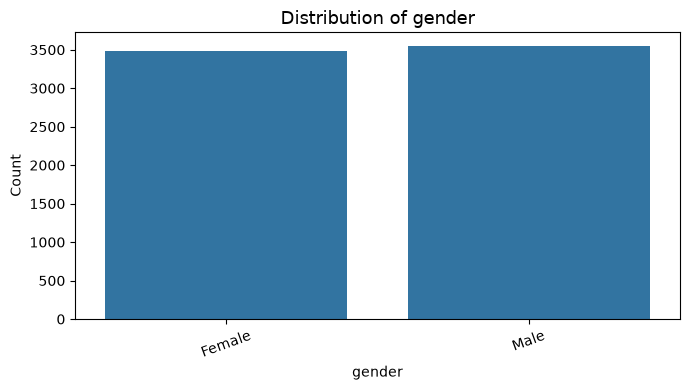

Feature: SeniorCitizen



,Count,Percentage (%)
SeniorCitizen,,
0,5890,83.76
1,1142,16.24


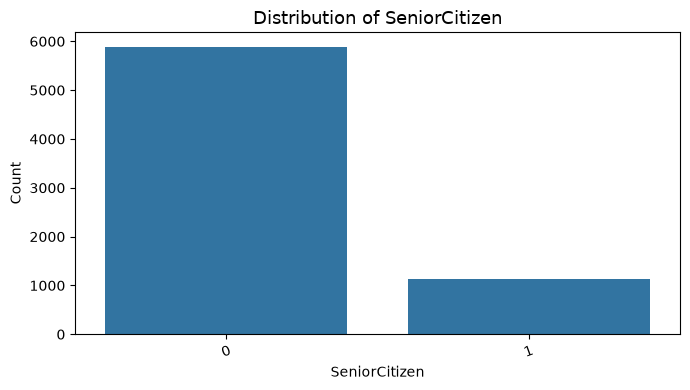

Feature: Partner



,Count,Percentage (%)
Partner,,
No,3639,51.75
Yes,3393,48.25


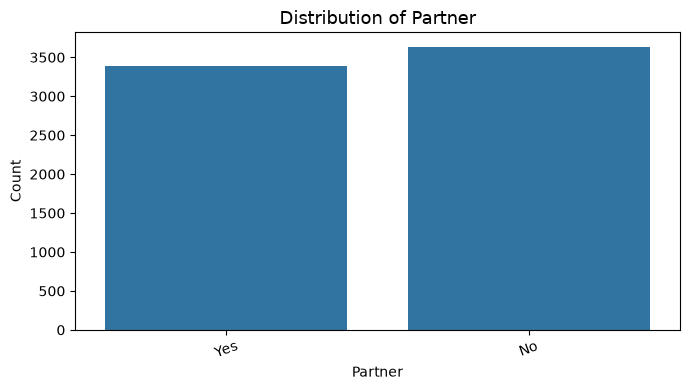

Feature: Dependents



,Count,Percentage (%)
Dependents,,
No,4933,70.15
Yes,2099,29.85


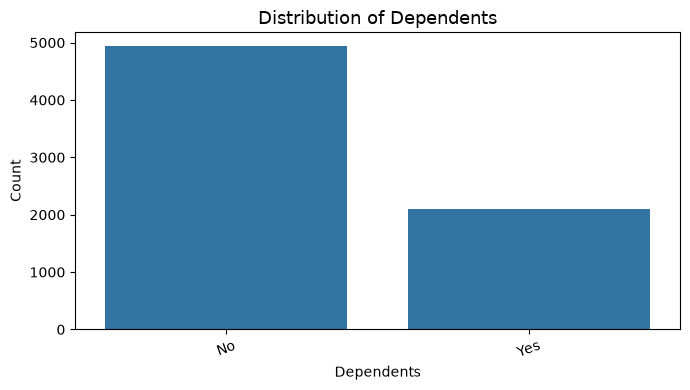

Feature: PhoneService



,Count,Percentage (%)
PhoneService,,
Yes,6352,90.33
No,680,9.67


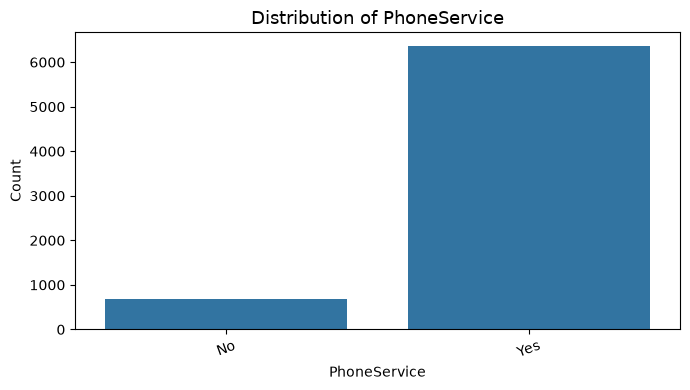

Feature: MultipleLines



,Count,Percentage (%)
MultipleLines,,
No,3385,48.14
Yes,2967,42.19
No phone service,680,9.67


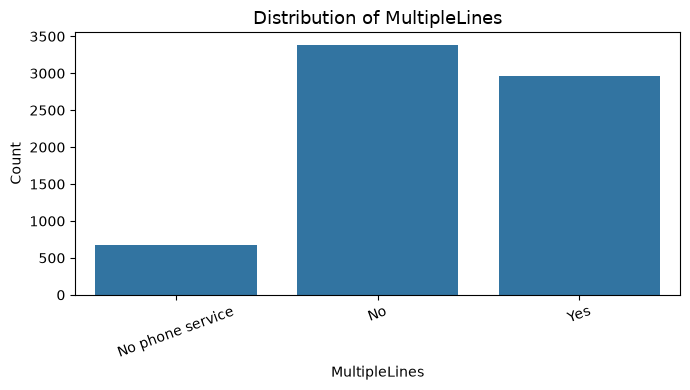

Feature: InternetService



,Count,Percentage (%)
InternetService,,
Fiber optic,3096,44.03
DSL,2416,34.36
No,1520,21.62


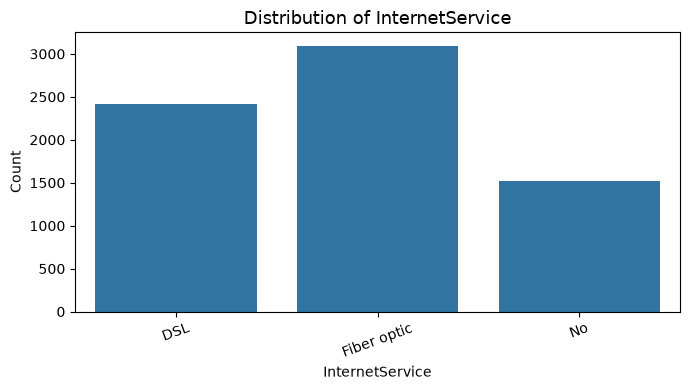

Feature: OnlineSecurity



,Count,Percentage (%)
OnlineSecurity,,
No,3497,49.73
Yes,2015,28.65
No internet service,1520,21.62


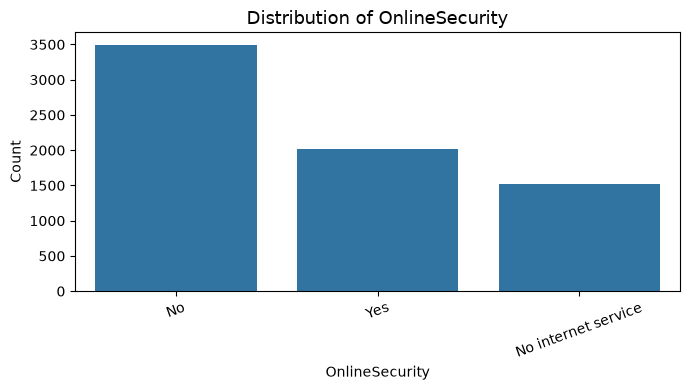

Feature: OnlineBackup



,Count,Percentage (%)
OnlineBackup,,
No,3087,43.90
Yes,2425,34.49
No internet service,1520,21.62


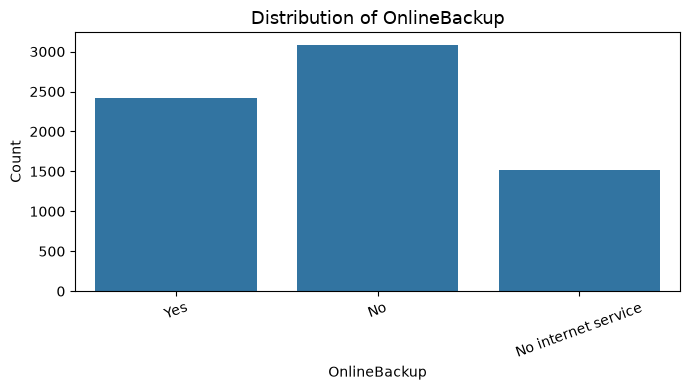

Feature: DeviceProtection



,Count,Percentage (%)
DeviceProtection,,
No,3094,44.00
Yes,2418,34.39
No internet service,1520,21.62


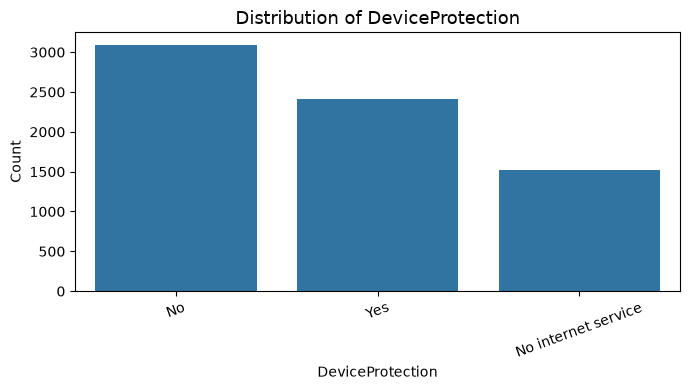

Feature: TechSupport



,Count,Percentage (%)
TechSupport,,
No,3472,49.37
Yes,2040,29.01
No internet service,1520,21.62


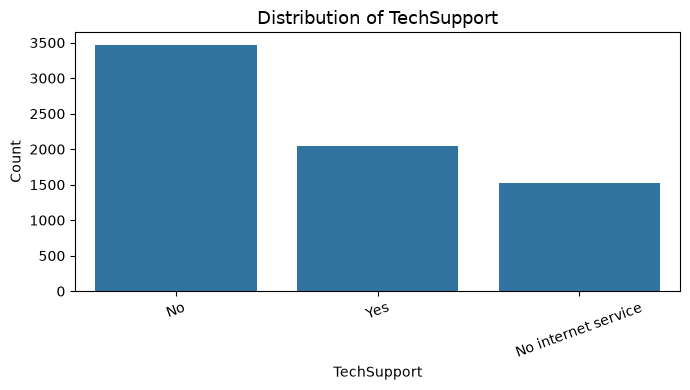

Feature: StreamingTV



,Count,Percentage (%)
StreamingTV,,
No,2809,39.95
Yes,2703,38.44
No internet service,1520,21.62


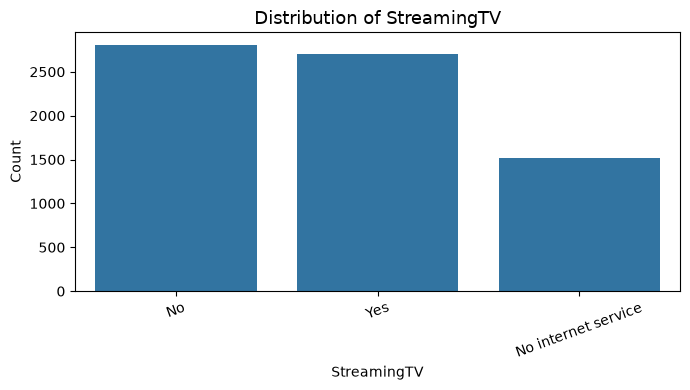

Feature: StreamingMovies



,Count,Percentage (%)
StreamingMovies,,
No,2781,39.55
Yes,2731,38.84
No internet service,1520,21.62


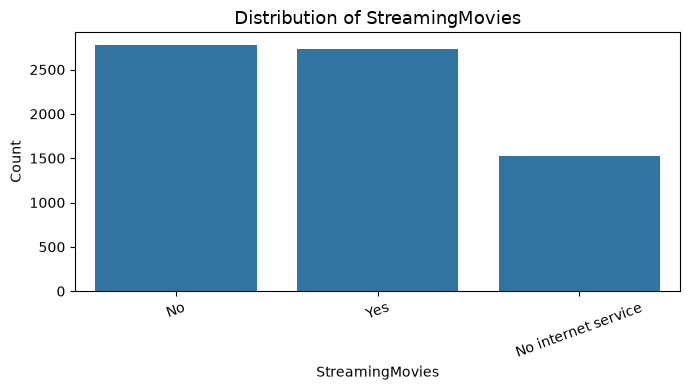

Feature: Contract



,Count,Percentage (%)
Contract,,
Month-to-month,3875,55.11
Two year,1685,23.96
One year,1472,20.93


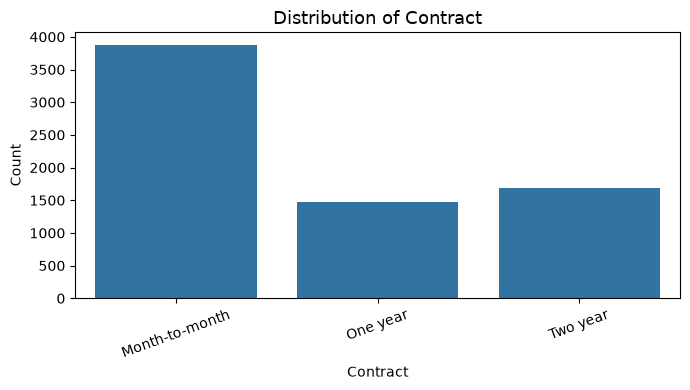

Feature: PaperlessBilling



,Count,Percentage (%)
PaperlessBilling,,
Yes,4168,59.27
No,2864,40.73


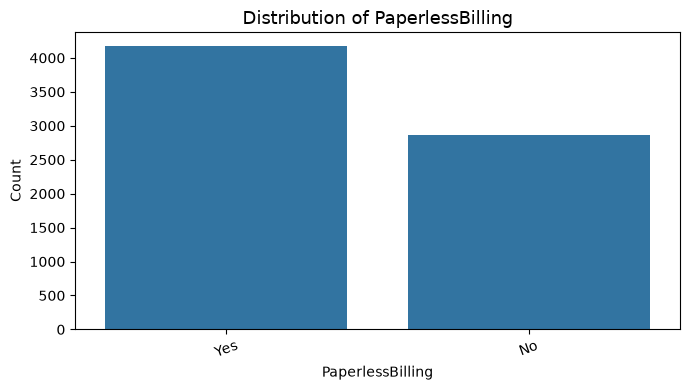

Feature: PaymentMethod



,Count,Percentage (%)
PaymentMethod,,
Electronic check,2365,33.63
Mailed check,1604,22.81
Bank transfer (automatic),1542,21.93
Credit card (automatic),1521,21.63


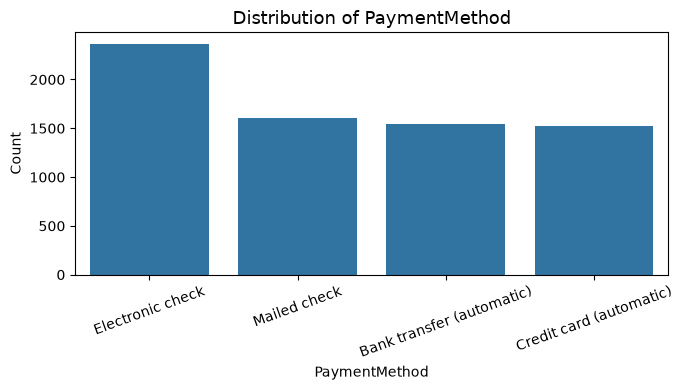

In [121]:
categorical_columns = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

for col in categorical_columns:

    print("=" * 80)
    print(f"Feature: {col}\n")
    frequency_table = pd.DataFrame({
        "Count": churn_cleaned_df[col].value_counts(),
        "Percentage (%)": (
            churn_cleaned_df[col]
            .value_counts(normalize=True)
            .mul(100)
            .round(2)
        )
    })

    display(frequency_table)


    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=churn_cleaned_df,
        x=col
    )

    plt.title(f"Distribution of {col}", fontsize=13)
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.xticks(rotation=20)

    plt.tight_layout()
    plt.show()

### Interpretation

The categorical feature analysis provides the following insights:

- The dataset contains an almost equal number of **male** and **female** customers, indicating a balanced gender distribution.

- Most customers are **not senior citizens** (83.76%), **do not have dependents** (70.15%), and are almost evenly split between having a partner and not having one.

- **Phone service** is widely adopted, with over 90% of customers subscribing to it.

- Among internet services, **Fiber optic** is the most common, followed by **DSL**, while approximately one-fifth of customers do not subscribe to any internet service.

- For value-added services such as **Online Security**, **Online Backup**, **Device Protection**, and **Tech Support**, the largest proportion of customers have not subscribed to these services.

- The distributions of **Streaming TV** and **Streaming Movies** are relatively balanced between subscribers and non-subscribers.

- More than half of the customers are on **month-to-month contracts**, while fewer customers have one-year or two-year contracts.

- **Paperless billing** is more common than traditional paper billing.

- **Electronic check** is the most frequently used payment method, whereas the remaining payment methods have relatively similar usage.



## Contract Type vs Customer Churn


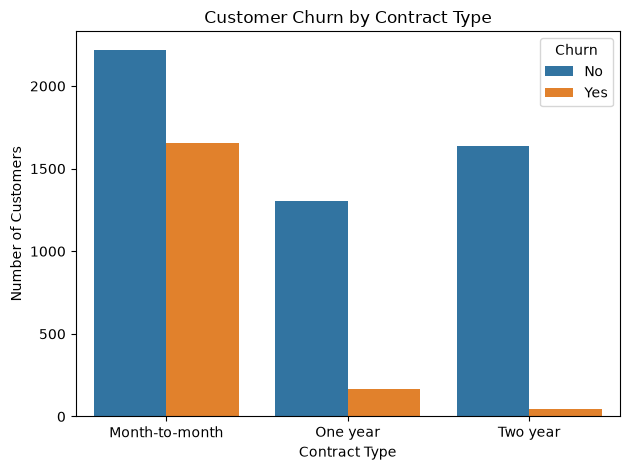

In [122]:
sns.countplot(data=churn_cleaned_df , x="Contract" , hue="Churn")
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [123]:
pd.crosstab(churn_cleaned_df["Contract"] , churn_cleaned_df["Churn"],normalize="index").round(2).mul(100)

Churn,No,Yes
Contract,,
Month-to-month,57.0,43.0
One year,89.0,11.0
Two year,97.0,3.0


### Interpretation

The analysis reveals a strong relationship between contract type and customer churn.

- Customers with **month-to-month contracts** have the highest churn rate, with **43%** leaving the company.

- Customers on **one-year contracts** have a much lower churn rate of **11%**, indicating better customer retention.

- Customers with **two-year contracts** exhibit the lowest churn rate at just **3%**, suggesting that long-term contracts are highly effective in retaining customers.

Overall, the results indicate that customers on shorter contracts are significantly more likely to churn than those committed to longer-term contracts. Therefore, **Contract** appears to be one of the strongest predictors of customer churn in the dataset.

## Internet Service vs Customer Churn

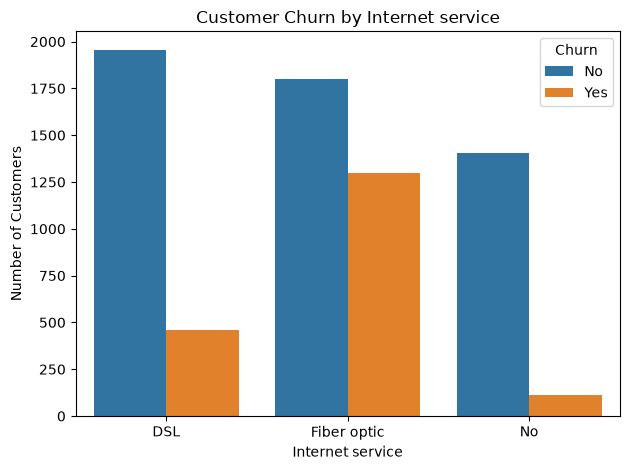

In [124]:
sns.countplot(data=churn_cleaned_df , x="InternetService" , hue="Churn")
plt.title("Customer Churn by Internet service")
plt.xlabel("Internet service")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [125]:
pd.crosstab(churn_cleaned_df["InternetService"] , churn_cleaned_df["Churn"] , normalize="index").mul(100).round(2)

Churn,No,Yes
InternetService,,
DSL,81.00,19.00
Fiber optic,58.11,41.89
No,92.57,7.43


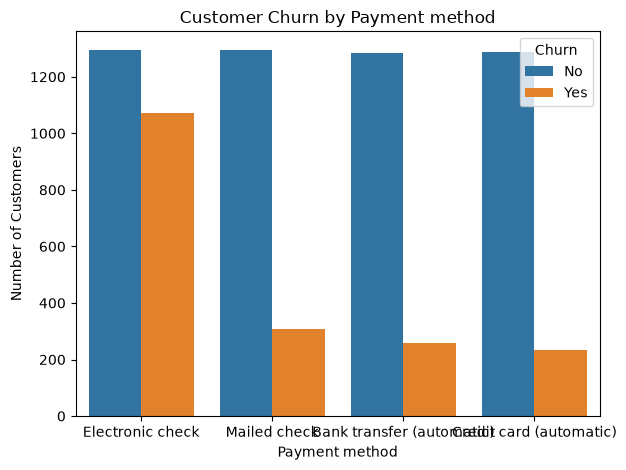

In [126]:
sns.countplot(data=churn_cleaned_df , x="PaymentMethod" , hue="Churn")
plt.title("Customer Churn by Payment method")
plt.xlabel("Payment method")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [127]:
pd.crosstab(churn_cleaned_df["PaymentMethod"] , churn_cleaned_df["Churn"] , normalize="index").mul(100).round(2).sort_values(by="Yes" , ascending=False)

Churn,No,Yes
PaymentMethod,,
Electronic check,54.71,45.29
Mailed check,80.80,19.20
Bank transfer (automatic),83.27,16.73
Credit card (automatic),84.75,15.25


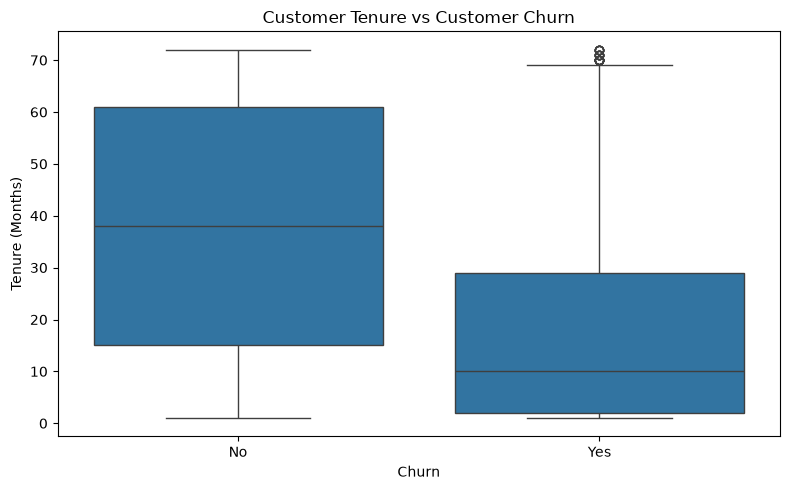

,Count,Mean,Median,Std,Min,Max
Churn,,,,,,
No,5163,37.65,38.0,24.08,1,72
Yes,1869,17.98,10.0,19.53,1,72


In [128]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=churn_cleaned_df,x="Churn",y="tenure")
plt.title("Customer Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.tight_layout()

plt.show()

tenure_summary = (churn_cleaned_df.groupby("Churn")["tenure"].agg(Count="count", Mean="mean", Median="median",Std="std",Min="min",Max="max").round(2))

display(tenure_summary)

## Monthly Charges vs Customer Churn


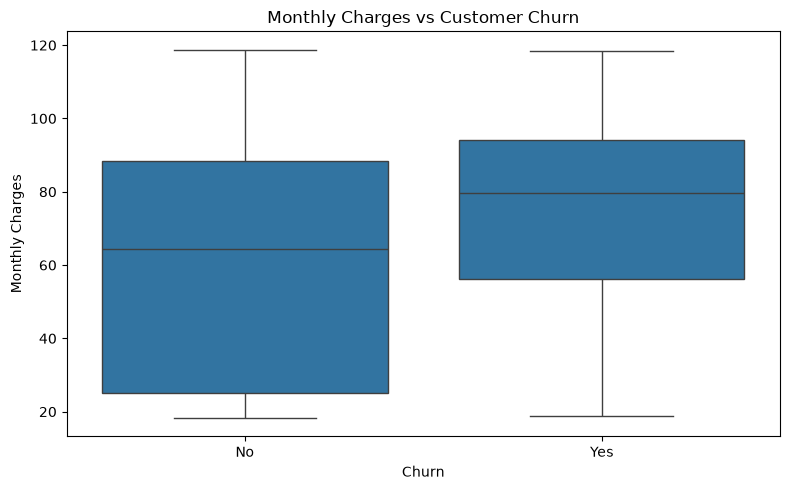

,Count,Mean,Median,Std,Min,Max
Churn,,,,,,
No,5163,61.31,64.45,31.09,18.25,118.75
Yes,1869,74.44,79.65,24.67,18.85,118.35


In [129]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=churn_cleaned_df,x="Churn",y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()

monthly_summary = (churn_cleaned_df.groupby("Churn")["MonthlyCharges"].agg(Count="count",Mean="mean",Median="median",Std="std",Min="min",Max="max").round(2))
display(monthly_summary)

## Total Charges vs Customer Churn

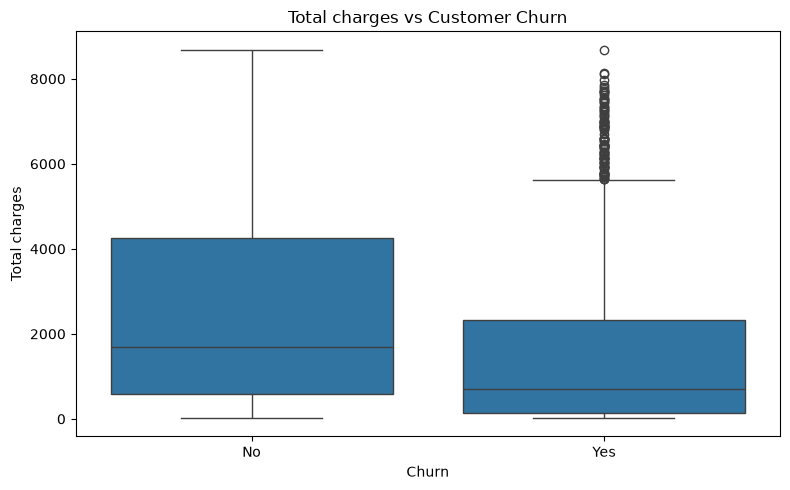

,Count,Mean,Median,Std,Min,Max
Churn,,,,,,
No,5163,2555.34,1683.60,2329.46,18.80,8672.45
Yes,1869,1531.80,703.55,1890.82,18.85,8684.80


In [130]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=churn_cleaned_df,x="Churn",y="TotalCharges")
plt.title("Total charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Total charges")
plt.tight_layout()
plt.show()
totalcharges_summary = (churn_cleaned_df.groupby("Churn")["TotalCharges"].agg(Count="count",Mean="mean",Median="median",Std="std",Min="min",Max="max").round(2))
display(totalcharges_summary)

# Correlation Analysis

In [131]:
numerical_columns

correlation_matrix = churn_cleaned_df[numerical_columns].corr().round(2)

correlation_matrix

,tenure,MonthlyCharges,TotalCharges
tenure,1.00,0.25,0.83
MonthlyCharges,0.25,1.00,0.65
TotalCharges,0.83,0.65,1.00


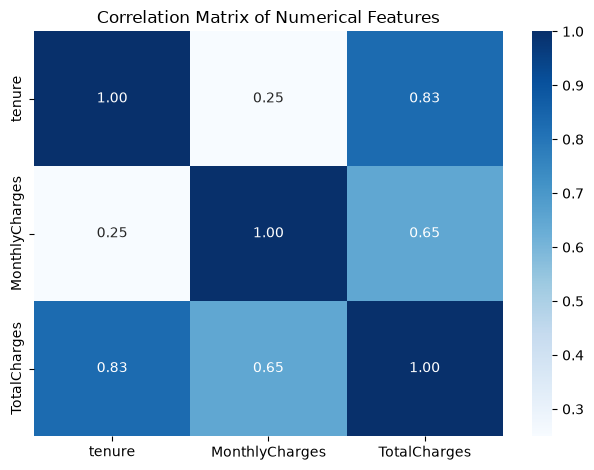

In [132]:
sns.heatmap(data=correlation_matrix , annot=True , cmap="Blues" ,fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")

plt.tight_layout()
plt.show()

### Interpretation

The correlation analysis reveals the following relationships among the numerical features:

- **tenure** and **TotalCharges** have a **strong positive correlation (0.83)**, indicating that customers who remain with the company for longer periods tend to accumulate higher total charges.

- **MonthlyCharges** and **TotalCharges** show a **moderate positive correlation (0.65)**, suggesting that customers with higher monthly bills generally accumulate higher total charges over time.

- **tenure** and **MonthlyCharges** exhibit a **weak positive correlation (0.25)**, indicating that the length of a customer's relationship with the company has only a slight association with their monthly subscription cost.

Overall, the observed relationships are consistent with the definition of the variables, as **TotalCharges** is influenced by both **tenure** and **MonthlyCharges**. No unexpected correlations are present among the numerical features.

# Feature Engineering



In [133]:
bins = [0, 12, 24, 48, 72]
labels = ["New","Regular","Established","Loyal"]

churn_cleaned_df["TenureGroup"] = pd.cut(churn_cleaned_df["tenure"],bins=bins,labels=labels,include_lowest=True)
churn_cleaned_df["TenureGroup"].value_counts().sort_index()

TenureGroup
New            2175
Regular        1024
Established    1594
Loyal          2239
Name: count, dtype: int64

## Create Number of Services

In [134]:
service_columns = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

churn_cleaned_df["NumberOfServices"] = churn_cleaned_df[service_columns].eq("Yes").sum(axis=1)

In [135]:
churn_cleaned_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TenureGroup,NumberOfServices
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,New,1
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,One year,No,Mailed check,56.95,1889.50,No,Established,2
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,New,2
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,Established,3
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,New,0


In [136]:
churn_cleaned_df["NumberOfServices"].value_counts().sort_index()

NumberOfServices
0    2213
1     966
2    1033
3    1117
4     850
5     569
6     284
Name: count, dtype: int64

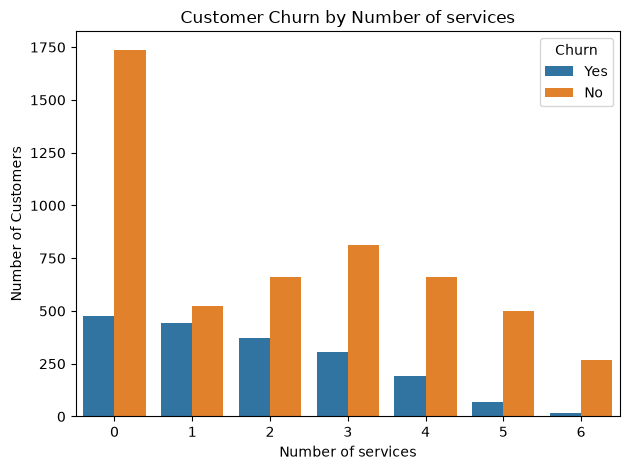

In [137]:
sns.countplot(data=churn_cleaned_df , x="NumberOfServices" , hue="Churn")
plt.title("Customer Churn by Number of services")
plt.xlabel("Number of services")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")
plt.tight_layout()
plt.show()

In [138]:
pd.crosstab(churn_cleaned_df["NumberOfServices"] , churn_cleaned_df["Churn"] , normalize="index").mul(100).round(2)

Churn,No,Yes
NumberOfServices,,
0,78.54,21.46
1,54.24,45.76
2,64.18,35.82
3,72.61,27.39
4,77.65,22.35
5,87.52,12.48
6,94.72,5.28


### Interpretation

The `NumberOfServices` feature reveals a clear relationship between customer engagement and churn.

- Customers subscribed to **only one additional service** have the highest churn rate (**45.76%**).

- As the number of subscribed services increases, the churn rate generally decreases.

- Customers with **five** and **six** additional services exhibit the lowest churn rates of **12.48%** and **5.28%**, respectively.

- Customers with **no additional services** have a moderate churn rate (**21.46%**), indicating that the highest churn is concentrated among customers with limited service adoption rather than those with no services.

Overall, customers who subscribe to a greater number of value-added services are more likely to remain with the company. This suggests that higher customer engagement is associated with improved customer retention, making `NumberOfServices` a valuable engineered feature for churn prediction.

# Data Preprocessing

## Separate Features and Target Variable


In [139]:
X = churn_cleaned_df.drop(columns="Churn")
y = churn_cleaned_df["Churn"]

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (7032, 21)
Shape of y: (7032,)


## Encode the Target Variable


In [140]:
y = y.map({
    "Yes":1,
    "No" : 0
})

print("Target Variable Distribution:")
print(y.value_counts())

print("\nUnique Values:")
print(y.unique())

Target Variable Distribution:
Churn
0    5163
1    1869
Name: count, dtype: int64

Unique Values:
[0 1]


In [141]:
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.20 , random_state=RANDOM_STATE,
                                                       stratify=y)

In [142]:
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (5625, 21)
X_test shape : (1407, 21)
y_train shape: (5625,)
y_test shape : (1407,)


## Identify Numerical and Categorical Features

In [143]:
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "NumberOfServices"
]

categorical_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod",
    "TenureGroup"
]

### Build the Preprocessing Pipeline

In [144]:
numerical_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("encoder" , OneHotEncoder(handle_unknown="ignore" , drop="if_binary"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num" , numerical_pipeline , numerical_features),
    ("cat" , categorical_pipeline , categorical_features)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

### Apply the Preprocessing Pipeline

In [145]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape :", X_test_processed.shape)

Processed X_train shape: (5625, 45)
Processed X_test shape : (1407, 45)


## Inspect the Processed Features

In [146]:
feature_names = preprocessor.get_feature_names_out()
print("Total Processed Features:", len(feature_names))
print()

for feature in feature_names:
    print(feature)

Total Processed Features: 45

num__tenure
num__MonthlyCharges
num__TotalCharges
num__NumberOfServices
cat__gender_Male
cat__SeniorCitizen_1
cat__Partner_Yes
cat__Dependents_Yes
cat__PhoneService_Yes
cat__MultipleLines_No
cat__MultipleLines_No phone service
cat__MultipleLines_Yes
cat__InternetService_DSL
cat__InternetService_Fiber optic
cat__InternetService_No
cat__OnlineSecurity_No
cat__OnlineSecurity_No internet service
cat__OnlineSecurity_Yes
cat__OnlineBackup_No
cat__OnlineBackup_No internet service
cat__OnlineBackup_Yes
cat__DeviceProtection_No
cat__DeviceProtection_No internet service
cat__DeviceProtection_Yes
cat__TechSupport_No
cat__TechSupport_No internet service
cat__TechSupport_Yes
cat__StreamingTV_No
cat__StreamingTV_No internet service
cat__StreamingTV_Yes
cat__StreamingMovies_No
cat__StreamingMovies_No internet service
cat__StreamingMovies_Yes
cat__Contract_Month-to-month
cat__Contract_One year
cat__Contract_Two year
cat__PaperlessBilling_Yes
cat__PaymentMethod_Bank transf

### Interpretation

The preprocessing pipeline successfully transformed the dataset into a numerical format suitable for machine learning.

- The four numerical features were standardized using `StandardScaler`.
- Binary categorical features were encoded into a single column using one-hot encoding with `drop="if_binary"`, reducing redundant features.
- Multi-category features were converted into multiple binary indicator columns using one-hot encoding.
- After preprocessing, the dataset contains **45 input features**, which will be used for training the machine learning models.

The preprocessing pipeline ensures that identical transformations are consistently applied to both training and testing data while preventing data leakage.

# EVALUATION FUNCTION (Reusable for ALL models)

In [150]:
def evaluate_model(model, model_name, X_train, y_train, X_test, y_test):
    y_train_pred = model.predict(X_train)
    y_train_prob = model.predict_proba(X_train)[:, 1]

    y_test_pred = model.predict(X_test)
    y_test_prob = model.predict_proba(X_test)[:, 1]

    train_metrics = {
        'Accuracy': accuracy_score(y_train, y_train_pred),
        'Precision': precision_score(y_train, y_train_pred, zero_division=0),
        'Recall': recall_score(y_train, y_train_pred, zero_division=0),
        'F1 Score': f1_score(y_train, y_train_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_train, y_train_prob)
    }

    test_metrics = {
        'Accuracy': accuracy_score(y_test, y_test_pred),
        'Precision': precision_score(y_test, y_test_pred, zero_division=0),
        'Recall': recall_score(y_test, y_test_pred, zero_division=0),
        'F1 Score': f1_score(y_test, y_test_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_test_prob)
    }
    
    return {
        'Model': model_name,
        'Train': train_metrics,
        'Test': test_metrics
    }

results_list = []
print("Evaluation function created successfully.")

Evaluation function created successfully.


# Baseline Model (DummyClassifier)

In [151]:
baseline_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent', random_state=42))
])

baseline_pipeline.fit(X_train, y_train)

print("Baseline model trained.")

Baseline model trained.


In [152]:
y_pred_baseline = baseline_pipeline.predict(X_test)
y_prob_baseline = baseline_pipeline.predict_proba(X_test)[:, 1]

print("Predictions made.")
print("First 10 predictions:", y_pred_baseline[:10])

Predictions made.
First 10 predictions: [0 0 0 0 0 0 0 0 0 0]


In [153]:
baseline_results = evaluate_model(
    baseline_pipeline, 
    'DummyClassifier',
    X_train, y_train,
    X_test, y_test
)

results_list.append(baseline_results)

print("TRAIN PERFORMANCE:")
for metric, value in baseline_results['Train'].items():
    print(f"  {metric}: {value:.4f}")

print("\nTEST PERFORMANCE:")
for metric, value in baseline_results['Test'].items():
    print(f"  {metric}: {value:.4f}")

TRAIN PERFORMANCE:
  Accuracy: 0.7342
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
  ROC-AUC: 0.5000

TEST PERFORMANCE:
  Accuracy: 0.7342
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
  ROC-AUC: 0.5000


# Interpretation

DummyClassifier predicts "No Churn" for every customer.

**Why all metrics are 0 for precision, recall, F1:**
- Model never predicts "Churn" (positive class)
- Precision = TP/(TP+FP) = 0/(0+0) = 0
- Recall = TP/(TP+FN) = 0/(0+374) = 0

**ROC-AUC = 0.50** means model is randomly guessing the positive class. This is the baseline.

**Train and Test are identical** because the model doesn't learn from data - it just predicts the majority class always.

**Business impact:** This model identifies zero churners. Company would lose all at-risk customers.

# Logistic Regression


In [156]:
lr_pipeline = Pipeline(steps=[
    ("preprocessor" , preprocessor),
    ("classifier" , LogisticRegression(random_state=RANDOM_STATE , max_iter=1000))
])
lr_pipeline.fit(X_train , y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['gender','SeniorCitizen','Partner',...,'TotalCharges','TenureGroup', 'NumberOfServices']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

In [158]:
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)
lr_results = evaluate_model(lr_pipeline, "LogisticRegression" , X_train , y_train , X_test ,y_test)

In [160]:
lr_results

{'Model': 'LogisticRegression',
 'Train': {'Accuracy': 0.8074666666666667,
  'Precision': 0.6691297208538588,
  'Recall': 0.5451505016722408,
  'F1 Score': 0.6008109104312569,
  'ROC-AUC': 0.8519878205803041},
 'Test': {'Accuracy': 0.7931769722814499,
  'Precision': 0.6334405144694534,
  'Recall': 0.5267379679144385,
  'F1 Score': 0.5751824817518248,
  'ROC-AUC': 0.8349532279690015}}

In [161]:
results_list.append(lr_results)

In [162]:
print("TRAIN PERFORMANCE:")
for metric, value in lr_results['Train'].items():
    print(f"  {metric}: {value:.4f}")

print("\nTEST PERFORMANCE:")
for metric, value in lr_results['Test'].items():
    print(f"  {metric}: {value:.4f}")


TRAIN PERFORMANCE:
  Accuracy: 0.8075
  Precision: 0.6691
  Recall: 0.5452
  F1 Score: 0.6008
  ROC-AUC: 0.8520

TEST PERFORMANCE:
  Accuracy: 0.7932
  Precision: 0.6334
  Recall: 0.5267
  F1 Score: 0.5752
  ROC-AUC: 0.8350


## Interpretation

Logistic Regression significantly outperforms the baseline.

**Key Improvements:**
- ROC-AUC improved from 0.50 to 0.835
- Recall at 52.7% means we now identify over half of churners
- Train vs Test gap is small (0.5-2%), indicating no overfitting

**Business Value:**
- Previously identified 0% of churners. Now identifying 53%.
- Precision of 63% means 2 out of 3 predicted churners are correct.
- False negatives still high (47% churners missed) - needs improvement.

**Next Steps:**
- Hyperparameter tuning may improve performance
- Explore other algorithms for better recall


#  Hyperparameter Tuning (Logistic Regression)


In [164]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l2'],
    'classifier__solver': ['liblinear', 'lbfgs']
}

cv = StratifiedKFold(n_splits=5 , shuffle=True , random_state=RANDOM_STATE)

grid_search = GridSearchCV(estimator=lr_pipeline , param_grid=param_grid , scoring="roc_auc" ,
                           cv=cv , n_jobs=-1)

grid_search.fit(X_train , y_train)

C:\Users\nisha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__penalty': ['l2'], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callabl

In [165]:
print("best parameters :" , grid_search.best_params_)
print("best cross validation roc auc score :" , grid_search.best_score_)

best parameters : {'classifier__C': 10, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear'}
best cross validation roc auc score : 0.8470745908476196


In [168]:

best_lr = grid_search.best_estimator_
y_pred_lr_tuned = best_lr.predict(X_test)
y_prob_lr_tuned = best_lr.predict_proba(X_test)
lr_tuned_results = evaluate_model(best_lr , "LogisticRegression(Tuned)" , X_train , y_train ,
                                  X_test , y_test)

In [169]:
results_list.append(lr_tuned_results)

In [170]:
print("TUNED LOGISTIC REGRESSION PERFORMANCE:")
print("\nTRAIN:")
for metric, value in lr_tuned_results['Train'].items():
    print(f"  {metric}: {value:.4f}")

print("\nTEST:")
for metric, value in lr_tuned_results['Test'].items():
    print(f"  {metric}: {value:.4f}")


TUNED LOGISTIC REGRESSION PERFORMANCE:

TRAIN:
  Accuracy: 0.8087
  Precision: 0.6721
  Recall: 0.5472
  F1 Score: 0.6032
  ROC-AUC: 0.8522

TEST:
  Accuracy: 0.7925
  Precision: 0.6306
  Recall: 0.5294
  F1 Score: 0.5756
  ROC-AUC: 0.8345


# Interpretation

Tuned model shows minimal improvement over initial version.

**Comparison (Initial vs Tuned - Test):**
- Accuracy: 79.32% vs 79.25% (slight drop)
- Recall: 52.67% vs 52.94% (minor gain)
- ROC-AUC: 83.50% vs 83.45% (similar)

**Why tuning didn't help much:**
- Default parameters were already near-optimal
- Small dataset means regularization has limited impact
- Cross-validation score (0.847) matches test performance, confirming good generalization

#  Cross-Validation

In [171]:
cv_scores = cross_val_score(best_lr, X_train, y_train, cv=5, scoring='roc_auc')

print("Cross-Validation Scores:", [round(x, 4) for x in cv_scores])
print("Mean ROC-AUC:", cv_scores.mean())
print("Std ROC-AUC:", cv_scores.std())

C:\Users\nisha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\nisha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Cross-Validation Scores: [np.float64(0.8394), np.float64(0.8734), np.float64(0.8417), np.float64(0.8219), np.float64(0.859)]
Mean ROC-AUC: 0.8470863329743212
Std ROC-AUC: 0.0176583282594634


C:\Users\nisha\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


# Confusion Matrix

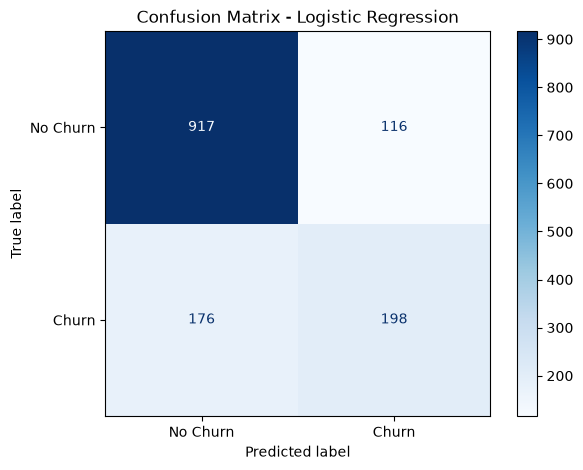

In [174]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_estimator(
    best_lr, 
    X_test, 
    y_test,
    display_labels=['No Churn', 'Churn'],
    ax=ax,
    cmap='Blues'
)
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


# Interpretation

Confusion Matrix shows:
- True Negatives: 917 (correctly predicted No Churn)
- False Positives: 116 (predicted Churn, but stayed)
- False Negatives: 176 (missed churners)
- True Positives: 198 (correctly predicted Churn)

**Business Impact:**
- 198 churners identified and can be targeted for retention
- 176 churners missed (costly false negatives)
- 116 customers incorrectly flagged (wasted retention efforts)
- Accuracy = (917+198)/1407 = 79.2%

# Classification Report


In [177]:
y_pred_final = best_lr.predict(X_test)
print(classification_report(y_test, y_pred_final, target_names=['No Churn', 'Churn']))

              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1033
       Churn       0.63      0.53      0.58       374

    accuracy                           0.79      1407
   macro avg       0.73      0.71      0.72      1407
weighted avg       0.78      0.79      0.79      1407



# Interpretation

Classification report shows:

**No Churn (Class 0):**
- Precision: 0.84 (84% of predicted non-churners are correct)
- Recall: 0.89 (89% of actual non-churners identified)
- F1: 0.86

**Churn (Class 1):**
- Precision: 0.63 (63% of predicted churners are correct)
- Recall: 0.53 (53% of actual churners identified)
- F1: 0.58

**Key Insight:**
- Model is better at identifying non-churners (89% recall) than churners (53% recall)
- This is expected due to class imbalance (73% non-churn)
- Business focus should be improving recall for churn class

# ROC Curve

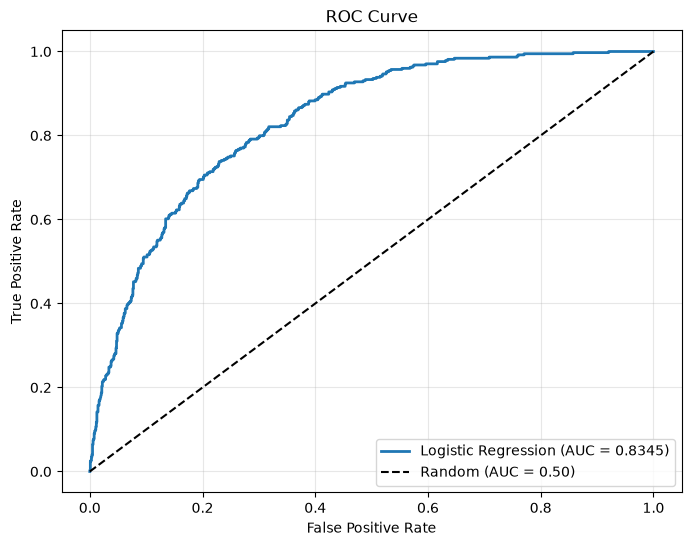

In [181]:
y_prob_final = best_lr.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob_final)
roc_auc = roc_auc_score(y_test, y_prob_final)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.4f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Interpretation

ROC curve shows excellent discrimination ability with AUC = 0.8345.

# Precision-Recall Curve